# AutoExperiment - Quick Start

**AutoML for Panel Data Econometrics**

This notebook shows how to run AutoExperiment in 5 lines of code using the classic Grunfeld investment dataset.

## What you'll learn
1. Run AutoExperiment with minimal configuration
2. Interpret the `summary()` output
3. Access `best_model` and `best_formula`
4. Compare top models
5. Generate an HTML report

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

from panelbox import AutoExperiment, load_grunfeld

print("PanelBox AutoExperiment loaded successfully!")

PanelBox AutoExperiment loaded successfully!


## 2. Load Data

The Grunfeld dataset contains investment data for 10 US firms over 20 years (1935-1954).

| Variable | Description |
|----------|-------------|
| `invest` | Gross investment |
| `value` | Market value of the firm |
| `capital` | Stock of plant and equipment |

In [2]:
data = load_grunfeld()
print(f"Panel: {data['firm'].nunique()} firms x {data['year'].nunique()} years = {len(data)} obs")
data.head()

Panel: 10 firms x 20 years = 200 obs


,firm,year,invest,value,capital
0,1,1935,317.6,3078.5,2.8
1,1,1936,391.8,4661.7,52.6
2,1,1937,410.6,5387.1,156.9
3,1,1938,257.7,2792.2,209.2
4,1,1939,330.8,4313.2,203.4


## 3. AutoExperiment in 5 Lines

AutoExperiment automates the entire panel data workflow:
- Generates variable transformations (lags, diffs)
- Selects variables via forward stepwise (BIC)
- Estimates Pooled OLS, Fixed Effects, Random Effects, First Difference
- Validates each model econometrically
- Ranks by composite score and auto-selects standard errors

In [3]:
auto = AutoExperiment(
    data=data,
    depvar="invest",
    entity_col="firm",
    time_col="year",
)

results = auto.run()

Phase 1: Variable transformations
  2 original + 4 transformed = 6 candidates
Phase 2: Forward stepwise selection
  Selecting for pooled_ols...
  [------------------------------] 0/4 Selection

  Selecting for fe...
  [#######-----------------------] 1/4 Selection

  Selecting for re...
  [###############---------------] 2/4 Selection

  Selecting for fd...
  [######################--------] 3/4 Selection

  [##############################] 4/4 Selection


...

    -> WARNING (BIC=1754.70, cov=robust)
  [#######-----------------------] 1/4 Estimation

    -> INVALID (BIC=1562.23, cov=robust)
  [###############---------------] 2/4 Estimation

    -> INVALID (BIC=1842.96, cov=robust)
  [######################--------] 3/4 Estimation

    -> VALID (BIC=nan, cov=nonrobust)
  [##############################] 4/4 Estimation


Phase 4: Hausman test (FE vs RE)
  Hausman: prefer RE (marked fe_capital_value as WARNING)
Phase 5: Ranking
Done.


## 4. Interpret the Summary

The `summary()` method provides a concise overview:
- **Best model**: Which estimator won (FE, RE, Pooled, FD)
- **Formula**: The selected specification
- **BIC**: Information criterion value
- **Status**: Whether the model passed all econometric tests
- **Cov type**: Auto-selected standard errors

In [4]:
print(results.summary())

══════════════════════════════════════════════════
AutoExperiment Results
══════════════════════════════════════════════════
Best model: First Difference
Formula:    invest ~ capital + value
BIC:        1754.7
R-squared:  0.809
Cov type:   nonrobust
Status:     VALID (all tests passed)
──────────────────────────────────────────────────
Models tested:     4
Combinations:      28
Variables tested:  6
Transformations:   2 types


## 5. Access the Best Model

The `best_model` attribute gives you the fitted `PanelResults` object.
You can use it for prediction, coefficient inspection, etc.

In [5]:
# Best formula and estimator
print(f"Best formula:   {results.best_formula}")
print(f"Best estimator: {results.best_estimator}")
print(f"Best cov type:  {results.best_cov_type}")
print()

# Coefficients of the best model
if results.best_model is not None:
    print("Coefficients:")
    print(results.best_model.summary())
else:
    print("No model selected (all models may have been classified as INVALID).")
    print("Try require_tests=False to see all models regardless of test results.")

Best formula:   invest ~ capital + value
Best estimator: fd
Best cov type:  nonrobust

Coefficients:
                     First Difference Estimation Results                      
Formula: invest ~ capital + value
Model:   First Difference
------------------------------------------------------------------------------
No. Observations:                 190
No. Entities:                      10
No. Time Periods:                  20
Degrees of Freedom:               188
R-squared:                     0.4453
Adj. R-squared:                0.4424
R-squared (within):            0.4453
Standard Errors:            nonrobust
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
capital              0.3479      0.0495   7.032  0.0000    0.2503    0.4455 ***
value                0.0892      0.0080  11.108  0.0000    0.0734    0.1051 ***
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1

## 6. Compare Top 3 Models

Use `compare_top()` to see all competing models side by side.

In [6]:
top3 = results.compare_top(n=3)
top3

,model_type,formula,bic,aic,rsq,rsq_adj,classification,n_vars,cov_type,score
0,fe,invest ~ capital + value,1562.226253,1555.629618,0.789935,0.777644,INVALID,2,robust,1750.226253
1,pooled_ols,invest ~ L1_value + capital + value,1754.699164,1741.711067,0.809126,0.806047,WARNING,3,robust,1794.699164
2,re,invest ~ value + capital,1842.959525,1833.064573,0.800281,0.798254,INVALID,2,robust,2030.959525


## 7. Visualize Results

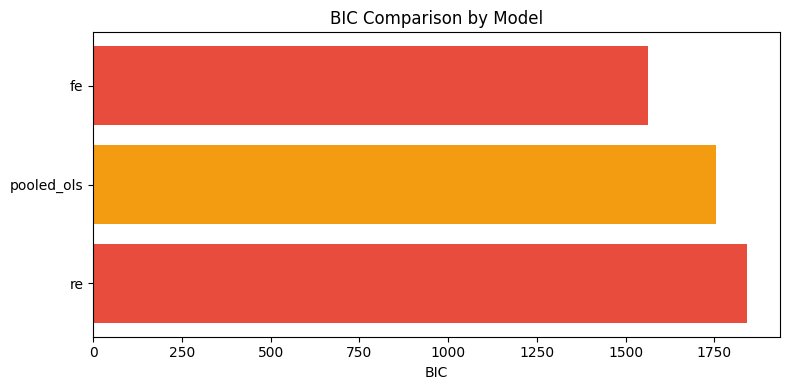

In [7]:
import matplotlib.pyplot as plt

fig = results.plot_bic_comparison()
if fig is not None:
    plt.show()

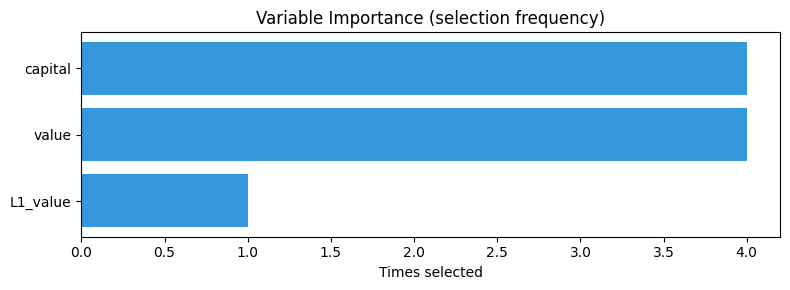

In [8]:
fig = results.plot_variable_importance()
if fig is not None:
    plt.show()

## 8. Full Ranking Table

In [9]:
results.ranking

,model_name,model_type,formula,bic,aic,rsq,rsq_adj,classification,n_vars,cov_type,score
0,fe_capital_value,fe,invest ~ capital + value,1562.226253,1555.629618,0.789935,0.777644,INVALID,2,robust,1750.226253
1,pooled_ols_L1_value_capital_value,pooled_ols,invest ~ L1_value + capital + value,1754.699164,1741.711067,0.809126,0.806047,WARNING,3,robust,1794.699164
2,re_value_capital,re,invest ~ value + capital,1842.959525,1833.064573,0.800281,0.798254,INVALID,2,robust,2030.959525
3,fd_capital_value,fd,invest ~ capital + value,NaN,NaN,0.445315,0.442365,VALID,2,nonrobust,NaN


## 9. Generate HTML Report

Generate a self-contained HTML report with all results, tests, and rankings.

In [10]:
html = results.report(filepath="autoexperiment_quickstart_report.html")
print(f"Report saved ({len(html):,} characters)")
print("Open autoexperiment_quickstart_report.html in your browser.")

Report saved (3,089 characters)
Open autoexperiment_quickstart_report.html in your browser.


## Summary

In this notebook we:
- Ran **AutoExperiment** on the Grunfeld dataset with a single call
- Examined the best model, formula, and standard errors
- Compared top models side by side
- Generated plots and an HTML report

**Next**: See `02_advanced_usage.ipynb` for custom transformations, sign constraints, and more.